<div style="width: 40%; clear: both;">
<div style="float: left; width: 20%;">
<img src="https://upload.wikimedia.org/wikipedia/commons/f/f7/Universidad_T%C3%A9cnica_Patricular_de_Loja.png", align="left" width="280" height="120">
</div>
</div>
<div style="float: right; width: 70%;">
<p style="margin: 0; padding-top: 32px; text-align:right; color:#003366; font-size:16px"><u>Análisis de datos y visualización (CICO2000)</u></p>
<p style="margin: 0; text-align:right; color:#999999; font-size:17px">Redes y Analítica de Datos</p>
</div>
</div>
<div style="width: 100%; clear: both;">
<div style="width:100%;">&nbsp;</div>


# Notebook 2.1 · Carga de datos desde archivos


En proyectos de datos se sigue el flujo **ETL** (*Extract–Transform–Load*): primero se **extraen** los datos de una fuente, luego se **transforman** y finalmente se **cargan** en una estructura adecuada para el análisis. En este notebook usted dará el primer paso: llevar un archivo real a memoria como un **DataFrame** de pandas y realizar una primera exploración.

**Objetivos**
1. Conocer el dataset *Optical Interconnection Network* y el significado de sus variables.
2. Cargar un archivo CSV en un DataFrame y ajustar los parámetros de lectura cuando el archivo no sigue el formato por defecto.
3. Inspeccionar los datos y obtener resúmenes con `describe()`, `value_counts()` y `groupby()`.
4. Generar gráficas básicas desde un DataFrame.
5. Crear funciones simples para automatizar tareas repetitivas.
6. Guardar los resultados con los métodos `to_*()`.

**Cómo usar este notebook**
- Ejecute las celdas **en orden** (`Shift + Enter`).
- Las celdas **⚠️ Ponga atención** destacan conceptos clave o errores frecuentes.
- La **sección 9** contiene los ejercicios que usted debe resolver.

| Sección | Contenido |
|---|---|
| 0 | Preparación del entorno |
| 1 | Conozca el dataset |
| 2 | Cargar el archivo en un DataFrame |
| 3 | Inspección inicial |
| 4 | Del DataFrame a listas, diccionarios y arreglos NumPy |
| 5 | Resumen descriptivo: `describe()` y `value_counts()` |
| 6 | Agrupación y síntesis: `groupby()` |
| 7 | Gráficas básicas con DataFrames |
| 8 | Funciones simples y escritura con `to_*()` |
| 9 | Ejercicios |

## 0. Preparación del entorno
Se importan las tres librerías de la semana: **pandas** (DataFrames), **NumPy** (arreglos y cálculo numérico) y **Matplotlib** (gráficas).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("pandas:", pd.__version__, "| NumPy:", np.__version__)

pandas: 2.3.3 | NumPy: 1.24.4


### 0.1 Ubicar el archivo `OIN.csv`
pandas lee el archivo desde una **ruta**. Si trabaja en **Google Colab**, primero suba el archivo a la sesión: ejecute la celda siguiente (quite los `#`) o use el ícono de carpeta 📁 del panel izquierdo. Si trabaja en Jupyter local, coloque `OIN.csv` en la misma carpeta del notebook.

In [2]:
# Solo en Google Colab: descomente las dos líneas y seleccione OIN.csv
# from google.colab import files
# files.upload()

RUTA = "OIN.csv"     # ruta del archivo; cámbiela si el archivo está en otra carpeta

> ⚠️ **Ponga atención:** en Colab, los archivos subidos se **borran al cerrar la sesión**. Si vuelve más tarde, súbalo de nuevo o guárdelo en Google Drive.

## 1. Conozca el dataset
Antes de escribir código de análisis, conviene entender **de dónde vienen los datos y qué representa cada fila**.

**Fuente:** *Optical Interconnection Network*, UCI Machine Learning Repository, https://archive.ics.uci.edu/dataset/449/optical+interconnection+network (licencia CC BY 4.0).

**Contexto.** Los datos provienen de **simulaciones** de una red de interconexión óptica en un sistema multiprocesador. Los nodos (procesadores) ejecutan hilos que intercambian mensajes por la red. En cada simulación se cambia la configuración (número de nodos, número de hilos, patrón de tráfico y carga) y se miden indicadores de desempeño como la utilización, los tiempos de espera y el tiempo de respuesta de la red.

**Cada fila es una configuración simulada.** Hay 640 filas, que resultan de combinar todos los valores de las variables de entrada:

$$2\ (\text{nodos}) \times 4\ (\text{hilos}) \times 4\ (\text{dist. espacial}) \times 2\ (\text{dist. temporal}) \times 10\ (T/R) = 640$$

### 1.1 Diccionario de datos

| Columna original | Nombre que usaremos | Tipo | Rol | Descripción |
|---|---|---|---|---|
| Node Number | `nodos` | Numérica discreta | Entrada | Número de nodos de la red: 16 o 64 |
| Thread Number | `hilos` | Numérica discreta | Entrada | Hilos por nodo: 4, 6, 8 o 10 |
| Spatial Distribution | `dist_espacial` | Categórica | Entrada | Patrón espacial del tráfico (a qué nodos se envían los mensajes): **UN** uniforme, **HR** *hot region* (región caliente), **BR** *bit reversal*, **PS** *perfect shuffle* |
| Temporal Distribution | `dist_temporal` | Categórica | Entrada | Patrón temporal de los mensajes: *Client-Server* o *Asynchronous* |
| T/R | `t_r` | Numérica continua | Entrada | Parámetro de carga de la simulación (0.1 a 1.0) |
| Processor Utilization | `util_procesador` | Numérica (0–1) | Salida | Proporción del tiempo que el procesador está ocupado |
| Channel Waiting Time | `espera_canal` | Numérica | Salida | Tiempo promedio de espera por un canal libre |
| Input Waiting Time | `espera_entrada` | Numérica | Salida | Tiempo promedio de espera en la entrada |
| Network Response Time | `tiempo_respuesta` | Numérica | Salida | Tiempo promedio de respuesta de la red |
| Channel Utilization | `util_canal` | Numérica (0–1) | Salida | Proporción del tiempo que los canales están ocupados |

Los tiempos se expresan en unidades de tiempo de la simulación.

> ⚠️ **Ponga atención:** distinguir **variables de entrada** (lo que se configura) y **variables de salida** (lo que se mide) le ayudará a formular buenas preguntas. Por ejemplo: *¿cómo cambia el tiempo de respuesta (salida) cuando aumenta la carga T/R (entrada)?*

### 1.2 Mirar el archivo antes de cargarlo
Un CSV es un **archivo de texto**. Leer sus primeras líneas sin pandas permite descubrir cómo está escrito: separador, separador decimal, encabezados y columnas vacías.

In [3]:
# open() abre el archivo como texto; leemos solo las 3 primeras líneas
with open(RUTA, encoding="utf-8") as f:
    for i in range(3):
        print(repr(f.readline()))    # repr() muestra caracteres ocultos como \n

'Node Number;Thread Number;Spatial Distribution;Temporal Distribution;T/R;Processor Utilization ;Channel Waiting Time;Input Waiting Time;Network Response Time;Channel Utilization;;;;;\n'
'64;4;UN;Client-Server;0,1;0,839546;1,974686;308,491814;700,514102;0,352431;;;;;\n'
'64;4;UN;Client-Server;0,2;0,827412;9,556437;291,037663;864,599227;0,506302;;;;;\n'


**¿Qué observa?**
- Las columnas están separadas por **punto y coma `;`**, no por coma.
- Los decimales usan **coma**: `0,839546` (formato habitual en Excel en español).
- Al final de cada línea hay `;;;;;`: existen **cinco columnas vacías** sin nombre.
- La columna `Processor Utilization ` tiene un **espacio al final** del nombre.

Estos detalles determinan cómo debemos usar `read_csv()`.

## 2. Cargar el archivo en un DataFrame
### 2.1 La familia de métodos `read_*()` y `to_*()`
pandas tiene un método de **lectura** `read_*()` y uno de **escritura** `to_*()` por cada formato. Se reemplaza el asterisco por el formato:

| Formato | Leer (archivo → DataFrame) | Guardar (DataFrame → archivo) |
|---|---|---|
| CSV | `pd.read_csv()` | `df.to_csv()` |
| Excel | `pd.read_excel()` | `df.to_excel()` |
| JSON | `pd.read_json()` | `df.to_json()` |
| Parquet | `pd.read_parquet()` | `df.to_parquet()` |
| SQL | `pd.read_sql()` | `df.to_sql()` |
| HTML | `pd.read_html()` | `df.to_html()` |

Observe que `read_*` es una función de **pandas** (`pd.`), porque crea un DataFrame nuevo, mientras que `to_*` es un método del **DataFrame** (`df.`), porque guarda uno que ya existe.

### 2.2 Primer intento: lectura con los valores por defecto

In [4]:
df_intento1 = pd.read_csv(RUTA)

print("Dimensiones:", df_intento1.shape)
df_intento1.head(3)

Dimensiones: (640, 1)


Node Number;Thread Number;Spatial Distribution;Temporal Distribution;T/R;Processor Utilization ;Channel Waiting Time;Input Waiting Time;Network Response Time;Channel Utilization;;;;;
64;4;UN;Client-Server;0 1;0 839546;1  974686;308 491814;700 514102;0                                        352431;;;;;                                                                                                                                    
                        2;0 827412;9  556437;291 037663;864 599227;0                                        506302;;;;;                                                                                                                                    
                        3;0 802605;27 027618;264 928002;839 372851;0                                        638516;;;;;

El resultado tiene **una sola columna**: pandas usa la coma como separador por defecto y, como el archivo usa `;`, interpretó cada línea completa como un único valor. Además, las comas decimales partieron algunos números.

> ⚠️ **Ponga atención:** que `read_csv()` **no dé error no significa que la carga sea correcta**. Revise siempre `shape` y `head()` después de cargar.

### 2.3 Segundo intento: indicar el separador con `sep`

In [5]:
df_intento2 = pd.read_csv(RUTA, sep=";")

print("Dimensiones:", df_intento2.shape)
print(df_intento2.dtypes)

Dimensiones: (640, 15)
Node Number                 int64
Thread Number               int64
Spatial Distribution       object
Temporal Distribution      object
T/R                        object
Processor Utilization      object
Channel Waiting Time       object
Input Waiting Time         object
Network Response Time      object
Channel Utilization        object
Unnamed: 10               float64
Unnamed: 11               float64
Unnamed: 12               float64
Unnamed: 13               float64
Unnamed: 14               float64
dtype: object


Ahora hay 15 columnas, pero aparecen dos problemas:
1. Las columnas de medidas (`T/R`, `Channel Waiting Time`…) son de tipo **texto** (`object` en pandas 2 / `str` en pandas 3), porque `0,839546` no se reconoce como número.
2. Hay columnas `Unnamed: 10` a `Unnamed: 14`, generadas por los `;;;;;` del final de cada línea.

In [6]:
# Con texto no se puede calcular: intentarlo produce un error
try:
    df_intento2["Channel Waiting Time"].mean()
except TypeError as e:
    print("TypeError:", str(e)[:90])

TypeError: Could not convert string '1,9746869,55643727,02761861,848511121,085884205,881088284,999115


### 2.4 Tercer intento: separador decimal con `decimal`

In [7]:
df = pd.read_csv(RUTA, sep=";", decimal=",")

print("Dimensiones:", df.shape)
print(df.dtypes)

Dimensiones: (640, 15)
Node Number                 int64
Thread Number               int64
Spatial Distribution       object
Temporal Distribution      object
T/R                       float64
Processor Utilization     float64
Channel Waiting Time      float64
Input Waiting Time        float64
Network Response Time     float64
Channel Utilization       float64
Unnamed: 10               float64
Unnamed: 11               float64
Unnamed: 12               float64
Unnamed: 13               float64
Unnamed: 14               float64
dtype: object


Las medidas ya son `float64` y los conteos, `int64`. Las columnas vacías siguen presentes: se eliminan a continuación.

### 2.5 Eliminar columnas vacías
`dropna(axis=1, how="all")` elimina las **columnas** (`axis=1`) cuyos valores son **todos** nulos (`how="all"`).

In [8]:
print("Valores no nulos en las columnas extra:")
print(df.iloc[:, 10:].notna().sum())       # todas tienen 0 valores

df = df.dropna(axis=1, how="all")
print("\nDimensiones después de eliminar columnas vacías:", df.shape)

Valores no nulos en las columnas extra:
Unnamed: 10    0
Unnamed: 11    0
Unnamed: 12    0
Unnamed: 13    0
Unnamed: 14    0
dtype: int64

Dimensiones después de eliminar columnas vacías: (640, 10)


### 2.6 Renombrar columnas con un diccionario
Los nombres con espacios, mayúsculas o símbolos (`T/R`, `Processor Utilization `) son incómodos de escribir y propensos a errores. Se renombran con `rename()` y un **diccionario** `{nombre_actual: nombre_nuevo}`.

In [9]:
print(list(df.columns))      # observe el espacio final en 'Processor Utilization '

# 1) Quitar espacios en los extremos de todos los nombres
df.columns = df.columns.str.strip()

# 2) Diccionario de equivalencias: clave = nombre original, valor = nombre nuevo
nombres = {
    "Node Number": "nodos",
    "Thread Number": "hilos",
    "Spatial Distribution": "dist_espacial",
    "Temporal Distribution": "dist_temporal",
    "T/R": "t_r",
    "Processor Utilization": "util_procesador",
    "Channel Waiting Time": "espera_canal",
    "Input Waiting Time": "espera_entrada",
    "Network Response Time": "tiempo_respuesta",
    "Channel Utilization": "util_canal",
}
df = df.rename(columns=nombres)
print(list(df.columns))

['Node Number', 'Thread Number', 'Spatial Distribution', 'Temporal Distribution', 'T/R', 'Processor Utilization ', 'Channel Waiting Time', 'Input Waiting Time', 'Network Response Time', 'Channel Utilization']
['nodos', 'hilos', 'dist_espacial', 'dist_temporal', 't_r', 'util_procesador', 'espera_canal', 'espera_entrada', 'tiempo_respuesta', 'util_canal']


> ⚠️ **Ponga atención**
> - Un nombre con espacio final (`"Processor Utilization "`) es **distinto** de `"Processor Utilization"`; si no lo limpia, obtendrá un `KeyError` al seleccionar la columna.
> - `rename()` devuelve un **DataFrame nuevo**: debe reasignarlo (`df = df.rename(...)`) para conservar el cambio.
> - Prefiera nombres en minúsculas, sin espacios ni tildes: así puede escribir `df["util_canal"]` sin errores.

### 2.7 Otros parámetros útiles de `read_csv()`

| Parámetro | Para qué sirve | Ejemplo |
|---|---|---|
| `sep` | Separador de columnas | `sep=";"` |
| `decimal` | Separador decimal | `decimal=","` |
| `usecols` | Cargar solo algunas columnas | `usecols=[0, 1, 4]` |
| `nrows` | Cargar solo las primeras filas | `nrows=100` |
| `encoding` | Codificación del texto | `encoding="latin-1"` |
| `header` | Fila que contiene los nombres | `header=None` si no hay encabezado |
| `na_values` | Valores que deben tratarse como nulos | `na_values=["-", "NA"]` |

In [10]:
# Ejemplo: cargar solo 4 columnas y las 5 primeras filas (útil con archivos grandes)
muestra = pd.read_csv(RUTA, sep=";", decimal=",", usecols=[0, 1, 2, 8], nrows=5)
muestra

,Node Number,Thread Number,Spatial Distribution,Network Response Time
0,64,4,UN,700.514102
1,64,4,UN,864.599227
2,64,4,UN,839.372851
3,64,4,UN,1256.053108
4,64,4,UN,1343.875577


## 3. Inspección inicial
Con los datos ya cargados, la primera tarea es **observarlos** antes de transformarlos o graficarlos.

In [11]:
df.head()          # primeras 5 filas

,nodos,hilos,dist_espacial,dist_temporal,t_r,util_procesador,espera_canal,espera_entrada,tiempo_respuesta,util_canal
0,64,4,UN,Client-Server,0.1,0.839546,1.974686,308.491814,700.514102,0.352431
1,64,4,UN,Client-Server,0.2,0.827412,9.556437,291.037663,864.599227,0.506302
2,64,4,UN,Client-Server,0.3,0.802605,27.027618,264.928002,839.372851,0.638516
3,64,4,UN,Client-Server,0.4,0.723403,61.848511,235.776888,1256.053108,0.767051
4,64,4,UN,Client-Server,0.5,0.721210,121.085884,189.680044,1343.875577,0.807812


In [12]:
df.tail(3)         # últimas 3 filas

,nodos,hilos,dist_espacial,dist_temporal,t_r,util_procesador,espera_canal,espera_entrada,tiempo_respuesta,util_canal
637,16,10,PS,Asynchronous,0.8,0.618230,905.326843,206.922631,1421.304936,0.962500
638,16,10,PS,Asynchronous,0.9,0.564482,1048.269897,154.713952,2371.043062,0.979375
639,16,10,PS,Asynchronous,1.0,0.515257,1184.647461,136.375081,2592.966463,0.980903


In [13]:
df.sample(5, random_state=42)      # 5 filas al azar; random_state hace que el resultado sea reproducible

,nodos,hilos,dist_espacial,dist_temporal,t_r,util_procesador,espera_canal,espera_entrada,tiempo_respuesta,util_canal
570,16,6,BR,Asynchronous,0.1,0.487785,1.119696,498.820922,19.484081,0.149965
265,64,8,BR,Asynchronous,0.6,0.501516,485.607819,347.748721,911.954125,0.585833
291,64,6,PS,Asynchronous,0.2,0.851833,10.140016,463.786026,237.913709,0.533646
597,16,10,BR,Asynchronous,0.8,0.441288,916.208130,268.419502,1446.767732,0.650833
174,64,6,UN,Asynchronous,0.5,0.786026,190.786957,311.382721,778.427756,0.863238


In [14]:
print("Filas y columnas:", df.shape)
df.info()

Filas y columnas: (640, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 640 entries, 0 to 639
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   nodos             640 non-null    int64  
 1   hilos             640 non-null    int64  
 2   dist_espacial     640 non-null    object 
 3   dist_temporal     640 non-null    object 
 4   t_r               640 non-null    float64
 5   util_procesador   640 non-null    float64
 6   espera_canal      640 non-null    float64
 7   espera_entrada    640 non-null    float64
 8   tiempo_respuesta  640 non-null    float64
 9   util_canal        640 non-null    float64
dtypes: float64(6), int64(2), object(2)
memory usage: 50.1+ KB


**Lectura de `info()`:** 640 filas, 10 columnas, **ningún valor nulo** (640 *non-null* en todas), 2 columnas de texto, 2 enteras y 6 decimales. También muestra la memoria utilizada.

> ⚠️ **Ponga atención:** `shape`, `columns` y `dtypes` son **atributos** (sin paréntesis); `head()`, `info()` y `describe()` son **métodos** (con paréntesis).

In [15]:
# Comprobaciones rápidas
print("Nulos por columna:\n", df.isna().sum(), sep="")
print("\nFilas duplicadas:", df.duplicated().sum())

Nulos por columna:
nodos               0
hilos               0
dist_espacial       0
dist_temporal       0
t_r                 0
util_procesador     0
espera_canal        0
espera_entrada      0
tiempo_respuesta    0
util_canal          0
dtype: int64

Filas duplicadas: 0


## 4. Del DataFrame a listas, diccionarios y arreglos NumPy
Las estructuras de la semana 3 siguen siendo útiles: muchas funciones devuelven listas o diccionarios, y NumPy es la base numérica sobre la que funciona pandas.

### 4.1 Listas

In [16]:
columnas = df.columns.tolist()                  # nombres de columnas como lista
espaciales = df["dist_espacial"].unique().tolist()   # valores distintos de una columna

print(columnas)
print(espaciales)
print("Número de patrones espaciales:", len(espaciales))

['nodos', 'hilos', 'dist_espacial', 'dist_temporal', 't_r', 'util_procesador', 'espera_canal', 'espera_entrada', 'tiempo_respuesta', 'util_canal']
['UN', 'HR', 'BR', 'PS']
Número de patrones espaciales: 4


### 4.2 Diccionarios
Cada fila puede representarse como un diccionario `{columna: valor}`, igual que un registro JSON.

In [17]:
fila0 = df.iloc[0].to_dict()          # primera fila como diccionario
print(fila0)
print("Tiempo de respuesta de la fila 0:", fila0["tiempo_respuesta"])

{'nodos': 64, 'hilos': 4, 'dist_espacial': 'UN', 'dist_temporal': 'Client-Server', 't_r': 0.1, 'util_procesador': 0.839546, 'espera_canal': 1.974686, 'espera_entrada': 308.491814, 'tiempo_respuesta': 700.514102, 'util_canal': 0.352431}
Tiempo de respuesta de la fila 0: 700.514102


In [18]:
# Lista de diccionarios (formato tipo JSON) -> DataFrame
registros = df.head(3).to_dict(orient="records")
print(registros[0])

pd.DataFrame(registros)               # se reconstruye la tabla

{'nodos': 64, 'hilos': 4, 'dist_espacial': 'UN', 'dist_temporal': 'Client-Server', 't_r': 0.1, 'util_procesador': 0.839546, 'espera_canal': 1.974686, 'espera_entrada': 308.491814, 'tiempo_respuesta': 700.514102, 'util_canal': 0.352431}


,nodos,hilos,dist_espacial,dist_temporal,t_r,util_procesador,espera_canal,espera_entrada,tiempo_respuesta,util_canal
0,64,4,UN,Client-Server,0.1,0.839546,1.974686,308.491814,700.514102,0.352431
1,64,4,UN,Client-Server,0.2,0.827412,9.556437,291.037663,864.599227,0.506302
2,64,4,UN,Client-Server,0.3,0.802605,27.027618,264.928002,839.372851,0.638516


### 4.3 Arreglos NumPy
Un arreglo NumPy (`ndarray`) guarda datos de **un mismo tipo** y permite cálculos vectorizados muy rápidos.

In [19]:
espera = df["espera_canal"].to_numpy()       # Series -> arreglo NumPy

print(type(espera), espera.shape, espera.dtype)
print("Primeros valores:", espera[:5])
print("Media:", np.mean(espera).round(2))
print("Percentil 90:", np.percentile(espera, 90).round(2))
print("Configuraciones con espera > 1000:", np.sum(espera > 1000))    # True cuenta como 1

<class 'numpy.ndarray'> (640,) float64
Primeros valores: [  1.974686   9.556437  27.027618  61.848511 121.085884]
Media: 377.46
Percentil 90: 972.57
Configuraciones con espera > 1000: 56


In [20]:
# Operación vectorizada: pasar utilización (0–1) a porcentaje sin escribir un ciclo
util_pct = df["util_procesador"].to_numpy() * 100
print(util_pct[:5].round(1))

[84.  82.7 80.3 72.3 72.1]


> ⚠️ **Ponga atención:** una `Series` de pandas tiene **índice y nombre**; un arreglo NumPy, no. Use NumPy cuando necesite cálculo numérico puro, y pandas cuando necesite conservar el contexto (etiquetas, columnas, tipos mixtos).

## 5. Resumen descriptivo: `describe()` y `value_counts()`
### 5.1 Variables numéricas con `describe()`
`describe()` calcula, para cada columna numérica, el conteo, la media, la desviación estándar, el mínimo, los cuartiles (25 %, 50 %, 75 %) y el máximo.

In [21]:
df.describe().round(3)

,nodos,hilos,t_r,util_procesador,espera_canal,espera_entrada,tiempo_respuesta,util_canal
count,640.000,640.000,640.000,640.000,640.000,640.000,640.000,640.000
mean,40.000,7.000,0.550,0.649,377.459,333.247,1504.248,26.348
std,24.019,2.238,0.287,0.195,381.975,233.722,1202.607,223.782
min,16.000,4.000,0.100,0.202,0.951,33.036,0.529,0.137
25%,16.000,5.500,0.300,0.493,29.248,137.731,580.676,0.588
50%,40.000,7.000,0.550,0.625,265.615,261.856,1232.150,0.774
75%,64.000,8.500,0.800,0.833,664.965,485.944,2115.327,0.906
max,64.000,10.000,1.000,0.987,1627.330,892.852,6065.737,2895.323


**¿Qué se puede leer aquí?**
- `nodos`, `hilos` y `t_r` tienen pocos valores posibles: son variables de diseño del experimento.
- Los tiempos (`espera_canal`, `tiempo_respuesta`) tienen desviaciones estándar grandes en relación con su media: hay **mucha variación** entre configuraciones.
- `util_canal` debería estar entre 0 y 1, pero su **máximo es 2895**. ¡Algo no cuadra!

In [22]:
# Revisemos las filas con utilización de canal mayor que 1
sospechosas = df[df["util_canal"] > 1]
print("Filas sospechosas:", len(sospechosas))
sospechosas

Filas sospechosas: 10


,nodos,hilos,dist_espacial,dist_temporal,t_r,util_procesador,espera_canal,espera_entrada,tiempo_respuesta,util_canal
120,64,4,PS,Client-Server,0.1,0.828573,1.934532,281.991851,0.529210,607.869882
121,64,4,PS,Client-Server,0.2,0.824084,9.550200,262.127869,0.633802,902.966929
122,64,4,PS,Client-Server,0.3,0.795685,26.339130,239.734762,0.718047,1042.409722
123,64,4,PS,Client-Server,0.4,0.739597,56.360073,230.163026,0.778299,1219.612435
124,64,4,PS,Client-Server,0.5,0.695053,126.209816,176.588953,0.822266,1202.936709
125,64,4,PS,Client-Server,0.6,0.624770,203.292633,142.075260,0.846927,1688.953232
126,64,4,PS,Client-Server,0.7,0.541929,287.763733,121.877978,0.840790,1904.053095
127,64,4,PS,Client-Server,0.8,0.487871,351.338531,107.055717,0.857222,2191.738331
128,64,4,PS,Client-Server,0.9,0.439760,420.470581,95.214030,0.860000,2752.001151
129,64,4,PS,Client-Server,1.0,0.400416,500.004944,77.396653,0.865191,2895.323131


> ⚠️ **Ponga atención: hallazgo de calidad de datos.** Las 10 filas corresponden a una misma configuración (64 nodos, 4 hilos, patrón PS) con sus 10 valores de T/R. En ellas, `tiempo_respuesta` tiene valores entre 0 y 1 y `util_canal` tiene valores en cientos o miles: todo indica que **los valores de esas dos columnas están intercambiados** en el archivo original. Por ahora solo **lo documentamos**; la corrección de datos se estudiará en la unidad de preparación y limpieza. Este es un buen ejemplo de por qué la exploración inicial es imprescindible: un resumen numérico permitió detectar un error que a simple vista pasaba desapercibido.

In [23]:
# describe() también funciona con columnas de texto
df.describe(exclude="number")      # todas las columnas que no son numéricas

,dist_espacial,dist_temporal
count,640,640
unique,4,2
top,UN,Client-Server
freq,160,320


Para columnas de texto, `describe()` informa el número de valores (`count`), cuántos son distintos (`unique`), el más frecuente (`top`) y su frecuencia (`freq`).

### 5.2 Variables categóricas con `value_counts()`

In [24]:
df["dist_espacial"].value_counts()

dist_espacial
UN    160
HR    160
BR    160
PS    160
Name: count, dtype: int64

In [25]:
# normalize=True devuelve proporciones en lugar de conteos
df["dist_temporal"].value_counts(normalize=True)

dist_temporal
Client-Server    0.5
Asynchronous     0.5
Name: proportion, dtype: float64

In [26]:
# También es útil con variables numéricas que tienen pocos valores
df["hilos"].value_counts().sort_index()

hilos
4     160
6     160
8     160
10    160
Name: count, dtype: int64

Todas las categorías tienen el **mismo número de filas** (160 por patrón espacial, 320 por patrón temporal): es un **diseño balanceado**, típico de los experimentos de simulación.

## 6. Agrupación y síntesis: `groupby()`
`groupby()` aplica la lógica **dividir – aplicar – combinar**: separa las filas en grupos según una columna, calcula una función en cada grupo y une los resultados.

### 6.1 Agrupar por una columna

In [27]:
# Tiempo de respuesta promedio según el patrón espacial de tráfico
df.groupby("dist_espacial")["tiempo_respuesta"].mean().sort_values(ascending=False).round(1)

dist_espacial
HR    2035.7
UN    1582.3
PS    1394.5
BR    1004.5
Name: tiempo_respuesta, dtype: float64

El patrón **HR** (*hot region*), en el que muchos mensajes se dirigen a una misma región de la red, tiene el mayor tiempo de respuesta promedio: concentrar el tráfico genera congestión.

In [28]:
# Efecto de la carga T/R sobre varias medidas
df.groupby("t_r")[["util_procesador", "espera_canal", "tiempo_respuesta"]].mean().round(2)

,util_procesador,espera_canal,tiempo_respuesta
t_r,,,
0.1,0.80,1.90,537.97
0.2,0.79,9.47,674.02
0.3,0.78,28.34,767.56
0.4,0.76,79.68,917.73
0.5,0.72,212.60,1207.26
0.6,0.65,418.09,1537.42
0.7,0.58,561.24,1905.94
0.8,0.52,700.82,2135.96
0.9,0.47,822.01,2605.17


Al aumentar `t_r`, los tiempos de espera y de respuesta **crecen** y la utilización del procesador **disminuye**: los procesadores pasan más tiempo esperando a la red.

### 6.2 Varias funciones con `agg()`

In [29]:
df.groupby("dist_temporal")["tiempo_respuesta"].agg(["count", "mean", "median", "max"]).round(1)

,count,mean,median,max
dist_temporal,,,,
Asynchronous,320,987.6,787.3,3444.7
Client-Server,320,2020.9,1718.2,6065.7


### 6.3 Agrupar por varias columnas

In [30]:
tabla = df.groupby(["nodos", "dist_espacial"])["util_procesador"].mean().round(3)
tabla

nodos  dist_espacial
16     BR               0.608
       HR               0.593
       PS               0.735
       UN               0.713
64     BR               0.659
       HR               0.438
       PS               0.723
       UN               0.723
Name: util_procesador, dtype: float64

In [31]:
# unstack() pasa el segundo nivel del índice a columnas: más fácil de leer
tabla.unstack()

dist_espacial,BR,HR,PS,UN
nodos,,,,
16,0.608,0.593,0.735,0.713
64,0.659,0.438,0.723,0.723


> ⚠️ **Ponga atención**
> - Seleccione la columna a resumir **después** de `groupby` (`df.groupby("a")["b"].mean()`); si no lo hace, pandas intentará calcular la media de todas las columnas y fallará con las de texto.
> - Recuerde las 10 filas sospechosas de la sección 5: afectan los promedios de `tiempo_respuesta` y `util_canal` de todos los grupos que las incluyen (por ejemplo, el patrón PS). Los resúmenes **dependen de la calidad de los datos**.

## 7. Gráficas básicas con DataFrames
Un DataFrame o una Series tienen el método `.plot()`, que usa Matplotlib internamente. El parámetro `kind` indica el tipo de gráfico.

| Pregunta | Tipo de gráfico | Código |
|---|---|---|
| ¿Cómo se distribuye una variable numérica? | Histograma | `df["col"].plot(kind="hist")` |
| ¿Cómo se comparan categorías? | Barras | `serie.plot(kind="bar")` |
| ¿Cómo cambia una variable en función de otra ordenada? | Líneas | `serie.plot(kind="line")` |
| ¿Hay relación entre dos variables numéricas? | Dispersión | `df.plot(kind="scatter", x=..., y=...)` |

### 7.1 Histograma

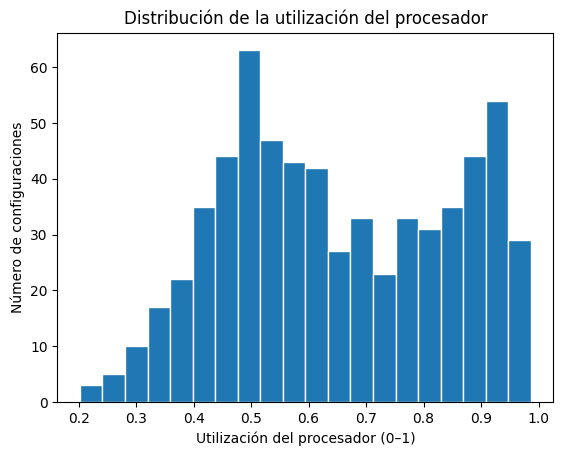

In [32]:
df["util_procesador"].plot(kind="hist", bins=20, edgecolor="white",
                           title="Distribución de la utilización del procesador")
plt.xlabel("Utilización del procesador (0–1)")
plt.ylabel("Número de configuraciones")
plt.show()

### 7.2 Barras

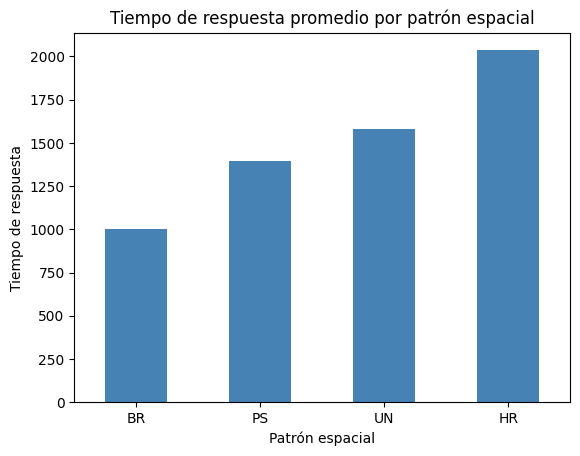

In [33]:
promedios = df.groupby("dist_espacial")["tiempo_respuesta"].mean().sort_values()

promedios.plot(kind="bar", color="steelblue", rot=0,
               title="Tiempo de respuesta promedio por patrón espacial")
plt.xlabel("Patrón espacial")
plt.ylabel("Tiempo de respuesta")
plt.show()

### 7.3 Líneas

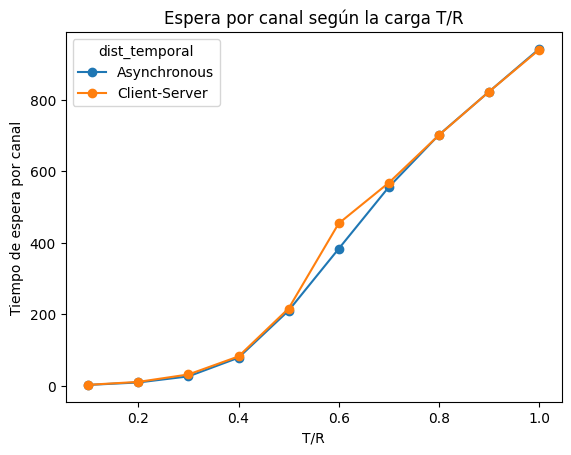

In [34]:
# Una línea por patrón temporal: unstack() deja cada patrón en una columna
carga = df.groupby(["t_r", "dist_temporal"])["espera_canal"].mean().unstack()

carga.plot(kind="line", marker="o", title="Espera por canal según la carga T/R")
plt.xlabel("T/R")
plt.ylabel("Tiempo de espera por canal")
plt.show()

### 7.4 Dispersión

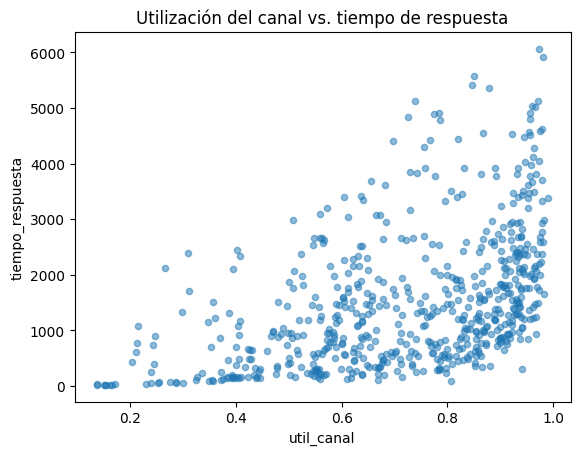

In [35]:
# Se excluyen las 10 filas sospechosas para no distorsionar la escala
limpias = df[df["util_canal"] <= 1]

limpias.plot(kind="scatter", x="util_canal", y="tiempo_respuesta", alpha=0.5,
             title="Utilización del canal vs. tiempo de respuesta")
plt.show()

> ⚠️ **Ponga atención:** elija el gráfico según la **pregunta** y el **tipo de variable**. Un histograma no sirve para una variable categórica, y un gráfico de líneas solo tiene sentido cuando el eje X tiene un orden (como `t_r`). Ponga siempre título y nombres a los ejes.

## 8. Funciones simples y escritura con `to_*()`
### 8.1 ¿Por qué crear funciones?
En la sección 2 necesitamos varias líneas para cargar el archivo correctamente. Si cada vez que abra el notebook repite esos pasos a mano, es fácil olvidar alguno. Una **función** encapsula el proceso y lo vuelve reutilizable.

Partes de una función: `def` + nombre + parámetros, la documentación (*docstring*) entre comillas triples, el cuerpo indentado y `return` con el resultado.

In [36]:
def cargar_oin(ruta):
    """Carga el CSV de la red óptica y devuelve un DataFrame listo para analizar."""
    datos = pd.read_csv(ruta, sep=";", decimal=",")    # separador y decimal del archivo
    datos = datos.dropna(axis=1, how="all")             # quita columnas vacías
    datos.columns = datos.columns.str.strip()           # quita espacios en los nombres
    return datos.rename(columns=nombres)                # nombres cortos (diccionario de la sección 2.6)


df2 = cargar_oin(RUTA)
print(df2.shape)
print(df2.equals(df))     # True: la función reproduce exactamente los pasos manuales

(640, 10)
True


In [37]:
def resumen_rapido(datos):
    """Muestra dimensiones, nulos, duplicados y columnas de un DataFrame."""
    print(f"Filas: {datos.shape[0]} | Columnas: {datos.shape[1]}")
    print(f"Valores nulos: {datos.isna().sum().sum()} | Filas duplicadas: {datos.duplicated().sum()}")
    print("Columnas numéricas:", datos.select_dtypes("number").columns.tolist())


resumen_rapido(df)

Filas: 640 | Columnas: 10
Valores nulos: 0 | Filas duplicadas: 0
Columnas numéricas: ['nodos', 'hilos', 't_r', 'util_procesador', 'espera_canal', 'espera_entrada', 'tiempo_respuesta', 'util_canal']


In [38]:
def promedio_por_grupo(datos, grupo, variable):
    """Devuelve el promedio de 'variable' para cada valor de 'grupo', ordenado de mayor a menor."""
    return datos.groupby(grupo)[variable].mean().sort_values(ascending=False).round(2)


# La misma función sirve para responder distintas preguntas
print(promedio_por_grupo(df, "nodos", "espera_canal"))
print()
print(promedio_por_grupo(df, "dist_temporal", "espera_entrada"))

nodos
16    382.32
64    372.60
Name: espera_canal, dtype: float64

dist_temporal
Asynchronous     345.57
Client-Server    320.93
Name: espera_entrada, dtype: float64


> ⚠️ **Ponga atención:** una función que usa `print()` **muestra** resultados, pero no los entrega; una función con `return` **devuelve** un valor que puede guardar en una variable y seguir usando. Use `return` cuando el resultado vaya a reutilizarse.

### 8.2 Guardar resultados con `to_*()`
Después de cargar y preparar los datos, conviene guardar una copia **persistente** para no repetir el proceso.

In [39]:
# CSV con formato estándar: separador coma y punto decimal; index=False evita guardar el índice
df.to_csv("oin_preparado.csv", index=False)

# JSON como lista de registros (lista de diccionarios)
df.to_json("oin_preparado.json", orient="records", indent=1)

# Verificación: volver a leer los archivos guardados
print(pd.read_csv("oin_preparado.csv").shape)
print(pd.read_json("oin_preparado.json").shape)

(640, 10)
(640, 10)


In [40]:
# Así se ve el inicio del JSON generado
with open("oin_preparado.json", encoding="utf-8") as f:
    print(f.read(330))

[
 {
  "nodos":64,
  "hilos":4,
  "dist_espacial":"UN",
  "dist_temporal":"Client-Server",
  "t_r":0.1,
  "util_procesador":0.839546,
  "espera_canal":1.974686,
  "espera_entrada":308.491814,
  "tiempo_respuesta":700.514102,
  "util_canal":0.352431
 },
 {
  "nodos":64,
  "hilos":4,
  "dist_espacial":"UN",
  "dist_temporal":"Clie


In [41]:
# Parquet: formato columnar y comprimido (necesita la librería pyarrow, ya instalada en Colab)
try:
    df.to_parquet("oin_preparado.parquet", index=False)
    print(pd.read_parquet("oin_preparado.parquet").shape)
except ImportError:
    print("pyarrow no está instalado en este entorno; en Colab funciona directamente.")

(640, 10)


### 8.3 Una base de datos ligera: SQLite
La librería estándar `sqlite3` permite crear una base de datos en un archivo y consultarla con **SQL**. Con pandas se escribe con `to_sql()` y se lee con `read_sql()`.

In [42]:
import sqlite3

con = sqlite3.connect("oin.db")                               # crea (o abre) la base de datos
df.to_sql("simulaciones", con, if_exists="replace", index=False)

consulta = """
SELECT dist_espacial, COUNT(*) AS n, ROUND(AVG(tiempo_respuesta), 1) AS resp_media
FROM simulaciones
WHERE nodos = 16
GROUP BY dist_espacial
"""
resultado = pd.read_sql(consulta, con)                        # el resultado es un DataFrame
con.close()
resultado

,dist_espacial,n,resp_media
0,BR,80,876.5
1,HR,80,1712.0
2,PS,80,1304.4
3,UN,80,1431.7


> ⚠️ **Ponga atención**
> - Guardar en CSV **no conserva los tipos de datos** (todo se guarda como texto y se infiere al leer); Parquet sí los conserva y ocupa menos espacio.
> - Sin `index=False`, `to_csv()` agrega una columna extra con el índice, que al volver a leer aparece como `Unnamed: 0`.
> - Elija el formato según el uso: CSV para compartir y abrir en Excel, JSON para intercambiar con aplicaciones y APIs, Parquet para análisis con grandes volúmenes, SQL cuando necesite consultas.

## 9. Ejercicios
Resuelva cada ejercicio en la celda indicada. **Comente su código** y, cuando se pida, escriba una interpretación breve en una celda de texto.

### Ejercicio 1 · `read_csv()`
Cargue nuevamente `OIN.csv` en un DataFrame llamado `ej1`, pero **solo** con las columnas `Node Number`, `Spatial Distribution`, `T/R` y `Network Response Time` y las **primeras 80 filas**. Verifique con `shape` y `dtypes` que la carga sea correcta (los valores de `T/R` deben ser decimales).

*Pista:* combine `sep`, `decimal`, `usecols` y `nrows`.

In [43]:
# Ejercicio 1

### Ejercicio 2 · Inspección inicial
Usando `df`:
a) Muestre las últimas 4 filas.
b) Muestre 6 filas al azar con `random_state=7`.
c) ¿Cuántas columnas son numéricas y cuántas de texto? Responda con código.

In [44]:
# Ejercicio 2

### Ejercicio 3 · Listas y diccionarios
a) Cree una lista con los valores distintos de `hilos`, ordenada de menor a mayor.
b) Cree un diccionario cuyas claves sean los patrones de `dist_espacial` y cuyos valores sean el **máximo** de `espera_canal` de cada patrón. *Pista:* `groupby(...).max().to_dict()`.
c) Convierta la fila con índice 300 en un diccionario y muestre su `dist_temporal`.

In [45]:
# Ejercicio 3

### Ejercicio 4 · NumPy
a) Convierta la columna `espera_entrada` en un arreglo NumPy.
b) Calcule su media, su mediana y su desviación estándar con funciones de NumPy.
c) ¿Cuántas configuraciones tienen una espera de entrada mayor que la media?

In [46]:
# Ejercicio 4

### Ejercicio 5 · `describe()` y `value_counts()`
a) Obtenga `describe()` de `tiempo_respuesta` **solo** para las filas con `dist_temporal == "Asynchronous"` y compárelo con el de `"Client-Server"`.
b) Use `value_counts()` para contar cuántas filas hay por cada valor de `nodos`.
c) Escriba en una celda de texto cuál patrón temporal tiene mayor tiempo de respuesta mediano.

In [47]:
# Ejercicio 5

*Interpretación del ejercicio 5:*

### Ejercicio 6 · `groupby()`
a) Calcule la utilización promedio del procesador según el número de `hilos`. ¿Aumenta o disminuye al haber más hilos?
b) Agrupe por `nodos` y `dist_temporal` y calcule el promedio y el máximo de `espera_canal` con `agg()`.
c) Calcule el `tiempo_respuesta` promedio por `dist_espacial` con todas las filas y luego **excluyendo** las 10 filas sospechosas (`util_canal > 1`). ¿Qué patrón cambia y por qué?

In [48]:
# Ejercicio 6

*Interpretación del ejercicio 6:*

### Ejercicio 7 · Gráficas básicas
a) Construya un histograma de `espera_entrada` con 15 intervalos.
b) Construya un gráfico de barras con el promedio de `util_procesador` por `dist_espacial`.
c) Construya un gráfico de líneas que muestre cómo cambia el `tiempo_respuesta` promedio según `t_r`, con una línea por cada valor de `nodos`.
Incluya título y nombres de ejes en todos los gráficos.

In [49]:
# Ejercicio 7

### Ejercicio 8 · Funciones simples
Cree una función `filtrar_y_resumir(datos, columna, valor, variable)` que:
1. filtre las filas donde `columna == valor`;
2. devuelva (`return`) el `describe()` de `variable` para esas filas.

Pruébela con dos casos: `("dist_espacial", "HR", "tiempo_respuesta")` y `("nodos", 64, "util_canal")`.

In [50]:
# Ejercicio 8

### Ejercicio 9 · Escritura con `to_*()`
a) Cree un DataFrame con las filas de `nodos == 16` y las columnas `hilos`, `dist_espacial`, `t_r` y `tiempo_respuesta`.
b) Guárdelo como `oin_16nodos.csv` (sin índice) y como `oin_16nodos.json` (`orient="records"`).
c) Vuelva a leer ambos archivos y compruebe que tienen el mismo número de filas y columnas que el DataFrame original.

In [51]:
# Ejercicio 9

### Reflexión final
Responda brevemente en esta celda:
1. ¿Qué habría pasado en su análisis si no hubiera revisado `shape` y `dtypes` después del primer intento de carga?
2. ¿Qué resumen o gráfico le permitió detectar más rápido el problema de las 10 filas sospechosas?
3. ¿Qué formato elegiría para guardar este dataset si lo fuera a usar repetidamente en Python? ¿Por qué?

*Sus respuestas:*

## Resumen
- `pd.read_*()` lleva un archivo a memoria como DataFrame; `df.to_*()` lo guarda de forma persistente.
- Inspeccione el archivo y verifique la carga: separador (`sep`), separador decimal (`decimal`), columnas vacías y nombres de columnas.
- `head()`, `info()`, `shape` y `dtypes` confirman que la carga fue correcta; `describe()` y `value_counts()` resumen los datos y ayudan a detectar valores imposibles.
- `groupby()` permite comparar el comportamiento de una variable entre grupos.
- `.plot()` genera gráficos rápidos; elija el tipo según la pregunta.
- Las funciones evitan repetir código y reducen errores.

**Referencia del dataset:** Optical Interconnection Network. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/449/optical+interconnection+network